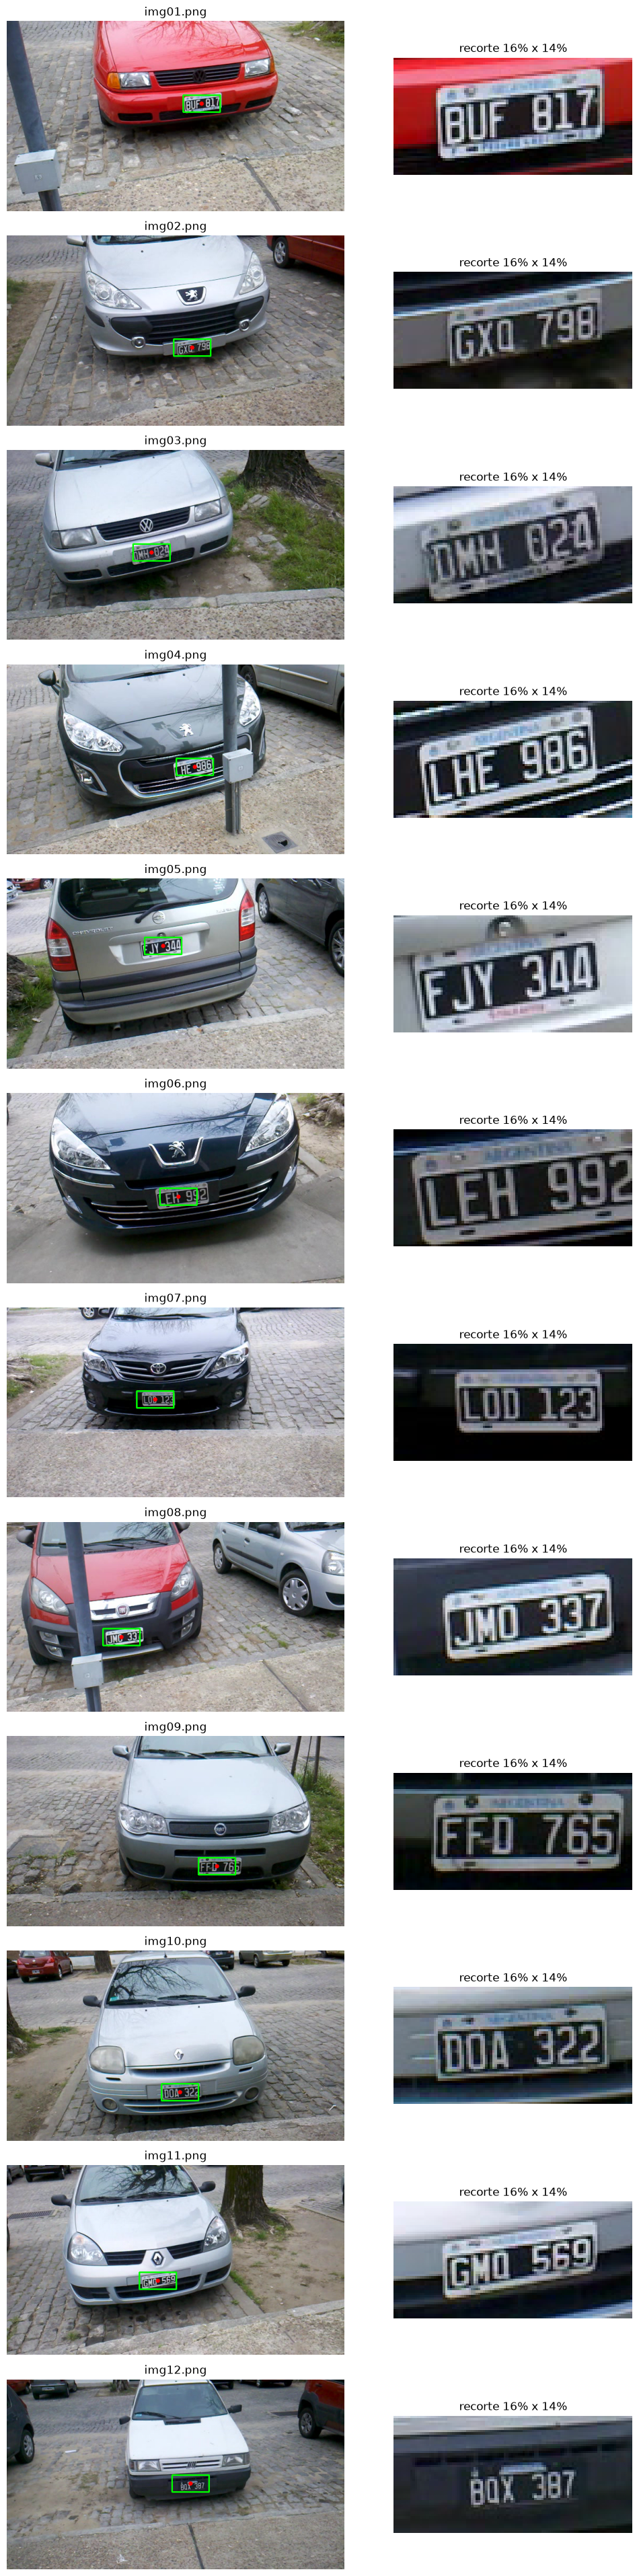

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# DETECTOR DE PATENTES (devuelve un punto dentro de la patente)
# ============================================================

def mapa_transiciones(negro):
    """Marca con 1 los píxeles donde, yendo de izquierda a derecha, se pasa de negro a claro:
    el píxel de la izquierda es negro y el actual no (borde de subida horizontal).
    Cada trazo blanco de una letra sobre la caja negra deja un 1 en su borde izquierdo."""
    t = np.zeros(negro.shape, np.uint8)
    t[:, 1:] = negro[:, :-1] & ~negro[:, 1:]
    return t


def detectar_punto(img, m_izq=0.20, m_der=0.20, m_sup=0.20, v_max=80, alto_min=3,
                   ventana_w=0.11, ventana_h=0.09, recentrar=True):
    """Devuelve (x, y, W, H): el punto central de la patente y el tamaño de la ventana,
    en coordenadas de la imagen original."""
    h_img, w_img = img.shape[:2]

    # 1) Zona útil: sacar márgenes izquierdo, derecho y superior (ahí nunca hay patentes)
    X0, X1, Y0 = int(m_izq * w_img), int((1 - m_der) * w_img), int(m_sup * h_img)
    roi = img[Y0:, X0:X1]

    # Tamaño de ventana: % de la imagen ORIGINAL (no de la recortada), ~ tamaño de una patente
    W, H = int(ventana_w * w_img), int(ventana_h * h_img)

    # 2) Píxeles negros: solo brillo bajo (V < v_max), sin mirar la saturación
    negro = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)[..., 2] < v_max

    # 3) Saltos negro -> claro
    saltos = mapa_transiciones(negro)

    # 3a) Erosión vertical: un salto sobrevive solo si tiene saltos arriba y abajo (alto_min px).
    #     Los bordes de las letras son verticales y sobreviven; los puntitos aislados desaparecen.
    saltos = cv2.erode(saltos, np.ones((alto_min, 1), np.uint8))
    # 3b) Dilatación: los trazos que sobrevivieron vuelven a engrosarse
    saltos = cv2.dilate(saltos, np.ones((3, 1), np.uint8))

    # 4) Cantidad de saltos en cada ventana (promedio móvil). La ventana con más saltos gana.
    #    BORDER_CONSTANT: fuera de la imagen cuenta como 0.
    cantidad = cv2.blur(saltos.astype(np.float32), (W, H), borderType=cv2.BORDER_CONSTANT)
    cy, cx = np.unravel_index(np.argmax(cantidad), cantidad.shape)

    # 4b) Recentrar: promedio de las posiciones de los saltos en una zona de 2W x 2H
    #     (de cy-H a cy+H y de cx-W a cx+W) alrededor del ganador, para que el punto
    #     caiga en el medio de las letras.
    if recentrar:
        y0, x0 = max(0, cy - H), max(0, cx - W)
        ys, xs = np.nonzero(saltos[y0:cy + H, x0:cx + W])
        cy, cx = int(ys.mean()) + y0, int(xs.mean()) + x0

    # 5) Volver a coordenadas de la imagen original
    return int(cx) + X0, int(cy) + Y0, W, H


def recortar(img, punto, frac_w=0.16, frac_h=0.14):
    """Recorte rectangular de frac_w*ancho x frac_h*alto centrado en 'punto'.
    Si el punto está cerca del borde, el recorte se desplaza (no se achica)."""
    h_img, w_img = img.shape[:2]
    CW, CH = int(frac_w * w_img), int(frac_h * h_img)
    x0 = min(max(0, punto[0] - CW // 2), w_img - CW)
    y0 = min(max(0, punto[1] - CH // 2), h_img - CH)
    return img[y0:y0 + CH, x0:x0 + CW]


# ============================================================
# VISUALIZACIÓN
# ============================================================

def ver_todas(rutas, frac_w=0.16, frac_h=0.14):
    """Por cada foto: a la izquierda la ventana ganadora (verde) y el punto (rojo);
    a la derecha el recorte final."""
    fig, ejes = plt.subplots(len(rutas), 2, figsize=(11, 3.2 * len(rutas)),
                             gridspec_kw={"width_ratios": [2.2, 1]})
    for fila, ruta in zip(ejes, rutas):
        img = cv2.imread(ruta, cv2.IMREAD_COLOR)
        cx, cy, W, H = detectar_punto(img)

        marcada = img.copy()
        cv2.rectangle(marcada, (cx - W // 2, cy - H // 2), (cx + W // 2, cy + H // 2), (0, 255, 0), 2)
        cv2.circle(marcada, (cx, cy), 4, (0, 0, 255), -1)

        fila[0].imshow(cv2.cvtColor(marcada, cv2.COLOR_BGR2RGB))
        fila[0].set_title(ruta[-9:]); fila[0].axis("off")
        fila[1].imshow(cv2.cvtColor(recortar(img, (cx, cy), frac_w, frac_h), cv2.COLOR_BGR2RGB))
        fila[1].set_title(f"recorte {int(frac_w*100)}% x {int(frac_h*100)}%"); fila[1].axis("off")
    plt.tight_layout()
    plt.show()


rutas = [f"../images/Patentes/img{i:02d}.png" for i in range(1, 13)]
ver_todas(rutas)

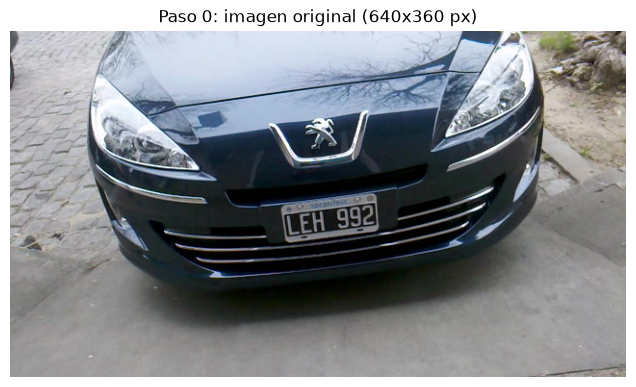

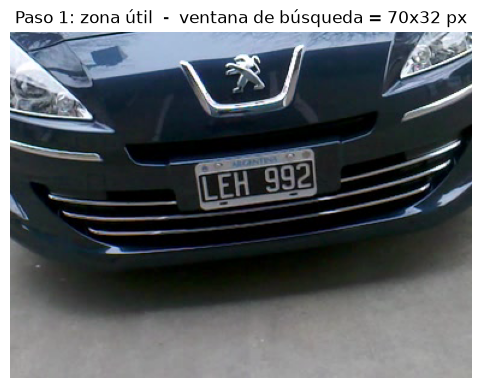

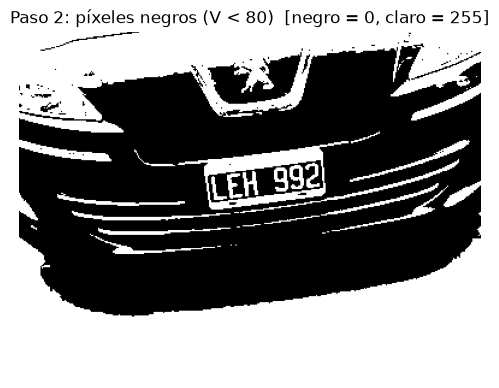

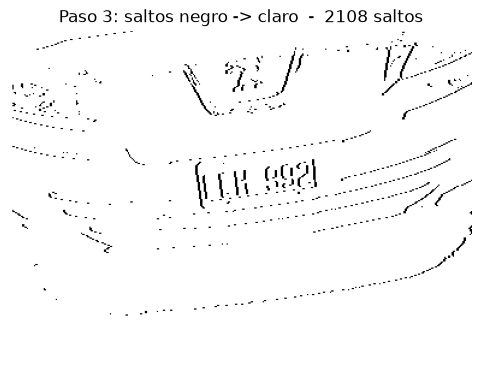

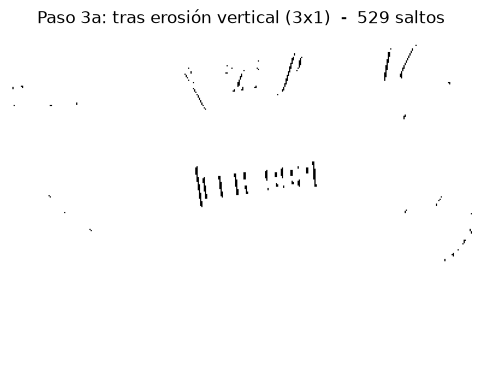

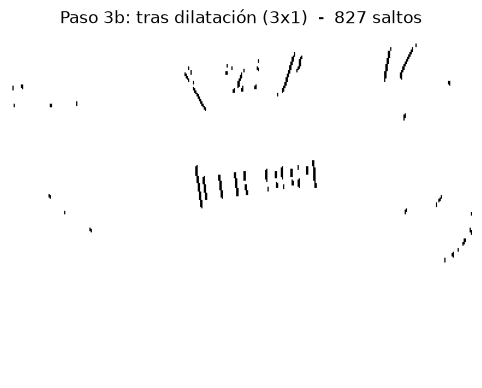

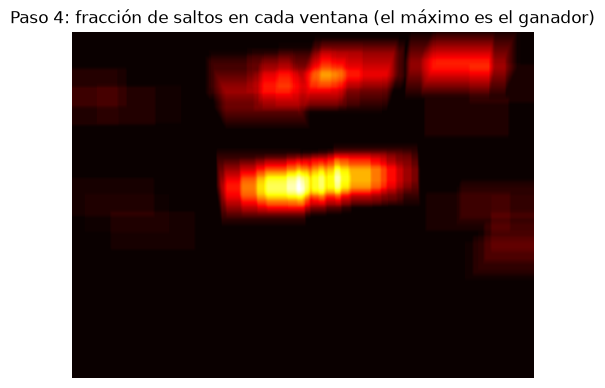

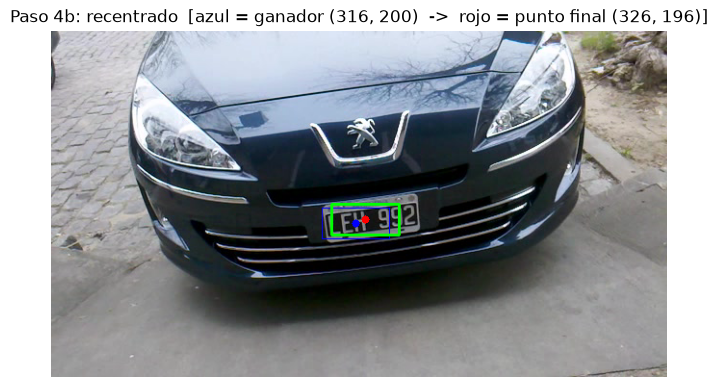

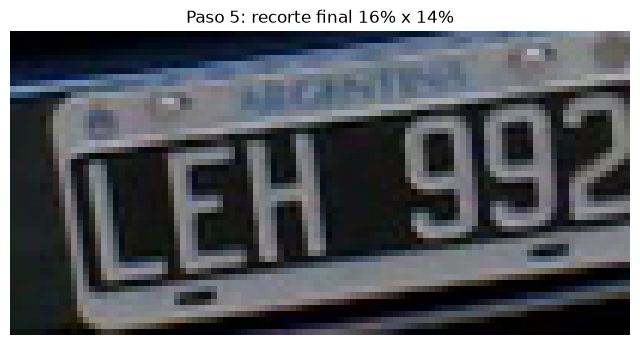

(326, 196)

In [29]:
def mostrar(imagen, titulo, cmap="gray"):
    """Muestra una imagen en su propia figura."""
    plt.figure(figsize=(8, 4.5))
    if imagen.ndim == 3:
        plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(imagen, cmap=cmap)
    plt.title(titulo); plt.axis("off"); plt.show()


def ver_pasos(ruta, m_izq=0.20, m_der=0.20, m_sup=0.20, v_max=80, salto=2, alto_min=3,
              ventana_w=0.11, ventana_h=0.09, frac_w=0.16, frac_h=0.14):
    """Mismo algoritmo que detectar_punto, mostrando una imagen por paso."""
    img = cv2.imread(ruta, cv2.IMREAD_COLOR)
    h_img, w_img = img.shape[:2]
    mostrar(img, f"Paso 0: imagen original ({w_img}x{h_img} px)")

    # Paso 1: zona útil
    X0, X1, Y0 = int(m_izq * w_img), int((1 - m_der) * w_img), int(m_sup * h_img)
    roi = img[Y0:, X0:X1]
    W, H = int(ventana_w * w_img), int(ventana_h * h_img)
    mostrar(roi, f"Paso 1: zona útil  -  ventana de búsqueda = {W}x{H} px")

    # Paso 2: píxeles negros (solo brillo)
    negro = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)[..., 2] < v_max
    mostrar(np.where(negro, 0, 255).astype(np.uint8),
            f"Paso 2: píxeles negros (V < {v_max})  [negro = 0, claro = 255]")

    # Paso 3: saltos negro -> claro
    saltos = mapa_transiciones(negro, salto)
    mostrar(255 - saltos * 255, f"Paso 3: saltos negro -> claro  -  {int(saltos.sum())} saltos")

    # Paso 3a: erosión vertical
    saltos = cv2.erode(saltos, np.ones((alto_min, 1), np.uint8))
    mostrar(255 - saltos * 255, f"Paso 3a: tras erosión vertical ({alto_min}x1)  -  {int(saltos.sum())} saltos")

    # Paso 3b: dilatación
    saltos = cv2.dilate(saltos, np.ones((3, 1), np.uint8))
    mostrar(255 - saltos * 255, f"Paso 3b: tras dilatación (3x1)  -  {int(saltos.sum())} saltos")

    # Paso 4: fracción de saltos en cada ventana; el máximo gana
    cantidad = cv2.blur(saltos.astype(np.float32), (W, H), borderType=cv2.BORDER_CONSTANT)
    cy, cx = np.unravel_index(np.argmax(cantidad), cantidad.shape)
    mostrar(cantidad, "Paso 4: fracción de saltos en cada ventana (el máximo es el ganador)", cmap="hot")
    px0, py0 = int(cx) + X0, int(cy) + Y0                   # ganador antes de recentrar

    # Paso 4b: recentrar (promedio de los saltos en una zona de 2x2 ventanas)
    y0, x0 = max(0, cy - H), max(0, cx - W)
    ys, xs = np.nonzero(saltos[y0:cy + H, x0:cx + W])
    cy, cx = int(ys.mean()) + y0, int(xs.mean()) + x0
    px, py = int(cx) + X0, int(cy) + Y0                     # punto final, en coordenadas originales

    marcada = img.copy()
    cv2.rectangle(marcada, (px0 - W // 2, py0 - H // 2), (px0 + W // 2, py0 + H // 2), (255, 0, 0), 1)
    cv2.rectangle(marcada, (px - W // 2, py - H // 2), (px + W // 2, py + H // 2), (0, 255, 0), 2)
    cv2.circle(marcada, (px0, py0), 4, (255, 0, 0), -1)
    cv2.circle(marcada, (px, py), 4, (0, 0, 255), -1)
    mostrar(marcada, f"Paso 4b: recentrado  [azul = ganador ({px0}, {py0})  ->  rojo = punto final ({px}, {py})]")

    # Paso 5: recorte final
    mostrar(recortar(img, (px, py), frac_w, frac_h), f"Paso 5: recorte final {int(frac_w*100)}% x {int(frac_h*100)}%")
    return px, py


ver_pasos("../images/Patentes/img06.png")

In [69]:
def preparar_binaria(recorte, umbral=127):
    """Grises -> estirado (min->0, máx->255) -> binaria (255 si > umbral)."""
    gris = cv2.cvtColor(recorte, cv2.COLOR_BGR2GRAY)
    estirado = cv2.normalize(gris, None, 0, 255, cv2.NORM_MINMAX)
    return estirado, np.where(estirado > umbral, 255, 0).astype(np.uint8)


def preparar_foto(ruta, frac_w=0.16, frac_h=0.14, umbral=127):
    img = cv2.imread(ruta, cv2.IMREAD_COLOR)
    cx, cy, W, H = detectar_punto(img)
    recorte = recortar(img, (cx, cy), frac_w, frac_h)
    estirado, binaria = preparar_binaria(recorte, umbral)
    return recorte, estirado, binaria


def componentes(binaria, area_min=6, alto_rel=(0.20, 0.70)):
    """Componentes conexas (8 vecinos) que podrían ser un carácter: área mínima para descartar
    puntitos, altura entre 20% y 70% del recorte y no más anchas que altas.
    Cada una: (x, y, ancho, alto, centro_x, centro_y), con el centro del recuadro que la rodea."""
    H = binaria.shape[0]
    n, _, st, _ = cv2.connectedComponentsWithStats(binaria, connectivity=4)
    comp = []
    for i in range(1, n):
        x, y, w, h, area = st[i]
        if area >= area_min and alto_rel[0] * H <= h <= alto_rel[1] * H and w <= h:
            comp.append((x, y, w, h, x + w / 2, y + h / 2))      # centro del recuadro, no de masa
    return comp


def dos_de_la_altura_mas_frecuente(comp, tol=1):
    """Busca la altura que más se repite (con tolerancia de 1 px, porque las alturas varían
    un píxel por redondeo) y, entre las componentes con esa altura, devuelve las dos más
    separadas en horizontal: así la recta queda mejor apoyada."""
    if len(comp) < 2:
        return None
    alturas = np.array([c[3] for c in comp])
    votos = [(np.abs(alturas - a) <= tol).sum() for a in alturas]   # cuántas comparten cada altura
    altura = alturas[int(np.argmax(votos))]
    grupo = sorted([c for c in comp if abs(c[3] - altura) <= tol], key=lambda c: c[4])
    if len(grupo) < 2:
        return None
    return grupo[0], grupo[-1], grupo, altura


def trazar_recta(vis, punto, pendiente, W, factor, color):
    """Dibuja de borde a borde la recta que pasa por 'punto' con la pendiente dada."""
    x0, y0 = punto
    y_izq = y0 + pendiente * (0 - x0)
    y_der = y0 + pendiente * ((W - 1) - x0)
    cv2.line(vis, (0, int(y_izq * factor)), ((W - 1) * factor, int(y_der * factor)), color, 1)


def ver_linea(rutas, umbral=127, factor=4, caja=0):
    """Izquierda: binaria con todas las componentes candidatas (celeste).
    Derecha: las 2 elegidas (verde) y 3 rectas paralelas con la misma pendiente:
      rojo     = por los centros de las dos cajas
      celeste  = desde la esquina superior izquierda de una de las cajas
      magenta  = desde la esquina inferior derecha de esa misma caja
    caja=0 usa la caja de la izquierda, caja=1 la de la derecha."""
    fig, ejes = plt.subplots(len(rutas), 2, figsize=(11, 2.3 * len(rutas)))
    ejes = np.atleast_2d(ejes)
    for fila, ruta in zip(ejes, rutas):
        recorte, estirado, binaria = preparar_foto(ruta, umbral=umbral)
        H, W = binaria.shape
        comp = componentes(binaria)

        vis_bin = cv2.resize(cv2.cvtColor(binaria, cv2.COLOR_GRAY2BGR), None, fx=factor, fy=factor,
                             interpolation=cv2.INTER_NEAREST)
        for x, y, w, h, _, _ in comp:
            cv2.rectangle(vis_bin, (x * factor, y * factor), ((x + w) * factor, (y + h) * factor), (255, 200, 0), 1)
        fila[0].imshow(cv2.cvtColor(vis_bin, cv2.COLOR_BGR2RGB))
        fila[0].set_title(f"{ruta[-9:]}: {len(comp)} componentes candidatas"); fila[0].axis("off")

        vis = cv2.resize(cv2.cvtColor(estirado, cv2.COLOR_GRAY2BGR), None, fx=factor, fy=factor,
                         interpolation=cv2.INTER_NEAREST)
        r = dos_de_la_altura_mas_frecuente(comp)
        if r is None:
            fila[1].set_title("no hay 2 componentes con la misma altura")
        else:
            c1, c2, grupo, altura = r
            pendiente = (c2[5] - c1[5]) / (c2[4] - c1[4])
            for c in (c1, c2):
                cv2.rectangle(vis, (c[0] * factor, c[1] * factor), ((c[0] + c[2]) * factor, (c[1] + c[3]) * factor), (0, 255, 0), 1)
                cv2.circle(vis, (int(c[4] * factor), int(c[5] * factor)), 4, (0, 0, 255), -1)

            c = (c1, c2)[caja]                                    # caja desde donde salen las otras 2 rectas
            sup_izq = (c[0], c[1])                                # esquina superior izquierda
            inf_der = (c[0] + c[2], c[1] + c[3])                  # esquina inferior derecha
            trazar_recta(vis, (c1[4], c1[5]), pendiente, W, factor, (0, 0, 255))      # por los centros
            trazar_recta(vis, sup_izq, pendiente, W, factor, (255, 255, 0))           # desde la esquina sup. izq.
            trazar_recta(vis, inf_der, pendiente, W, factor, (255, 0, 255))           # desde la esquina inf. der.
            for p, col in ((sup_izq, (255, 255, 0)), (inf_der, (255, 0, 255))):
                cv2.circle(vis, (int(p[0] * factor), int(p[1] * factor)), 4, col, -1)
            fila[1].set_title(f"{len(grupo)} con alto {int(altura)} | ángulo {np.degrees(np.arctan(pendiente)):.1f}°")
        fila[1].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); fila[1].axis("off")
    plt.tight_layout()
    plt.show()


rutas = [f"../images/Patentes/img{i:02d}.png" for i in range(1, 13)]
# ver_linea(rutas)


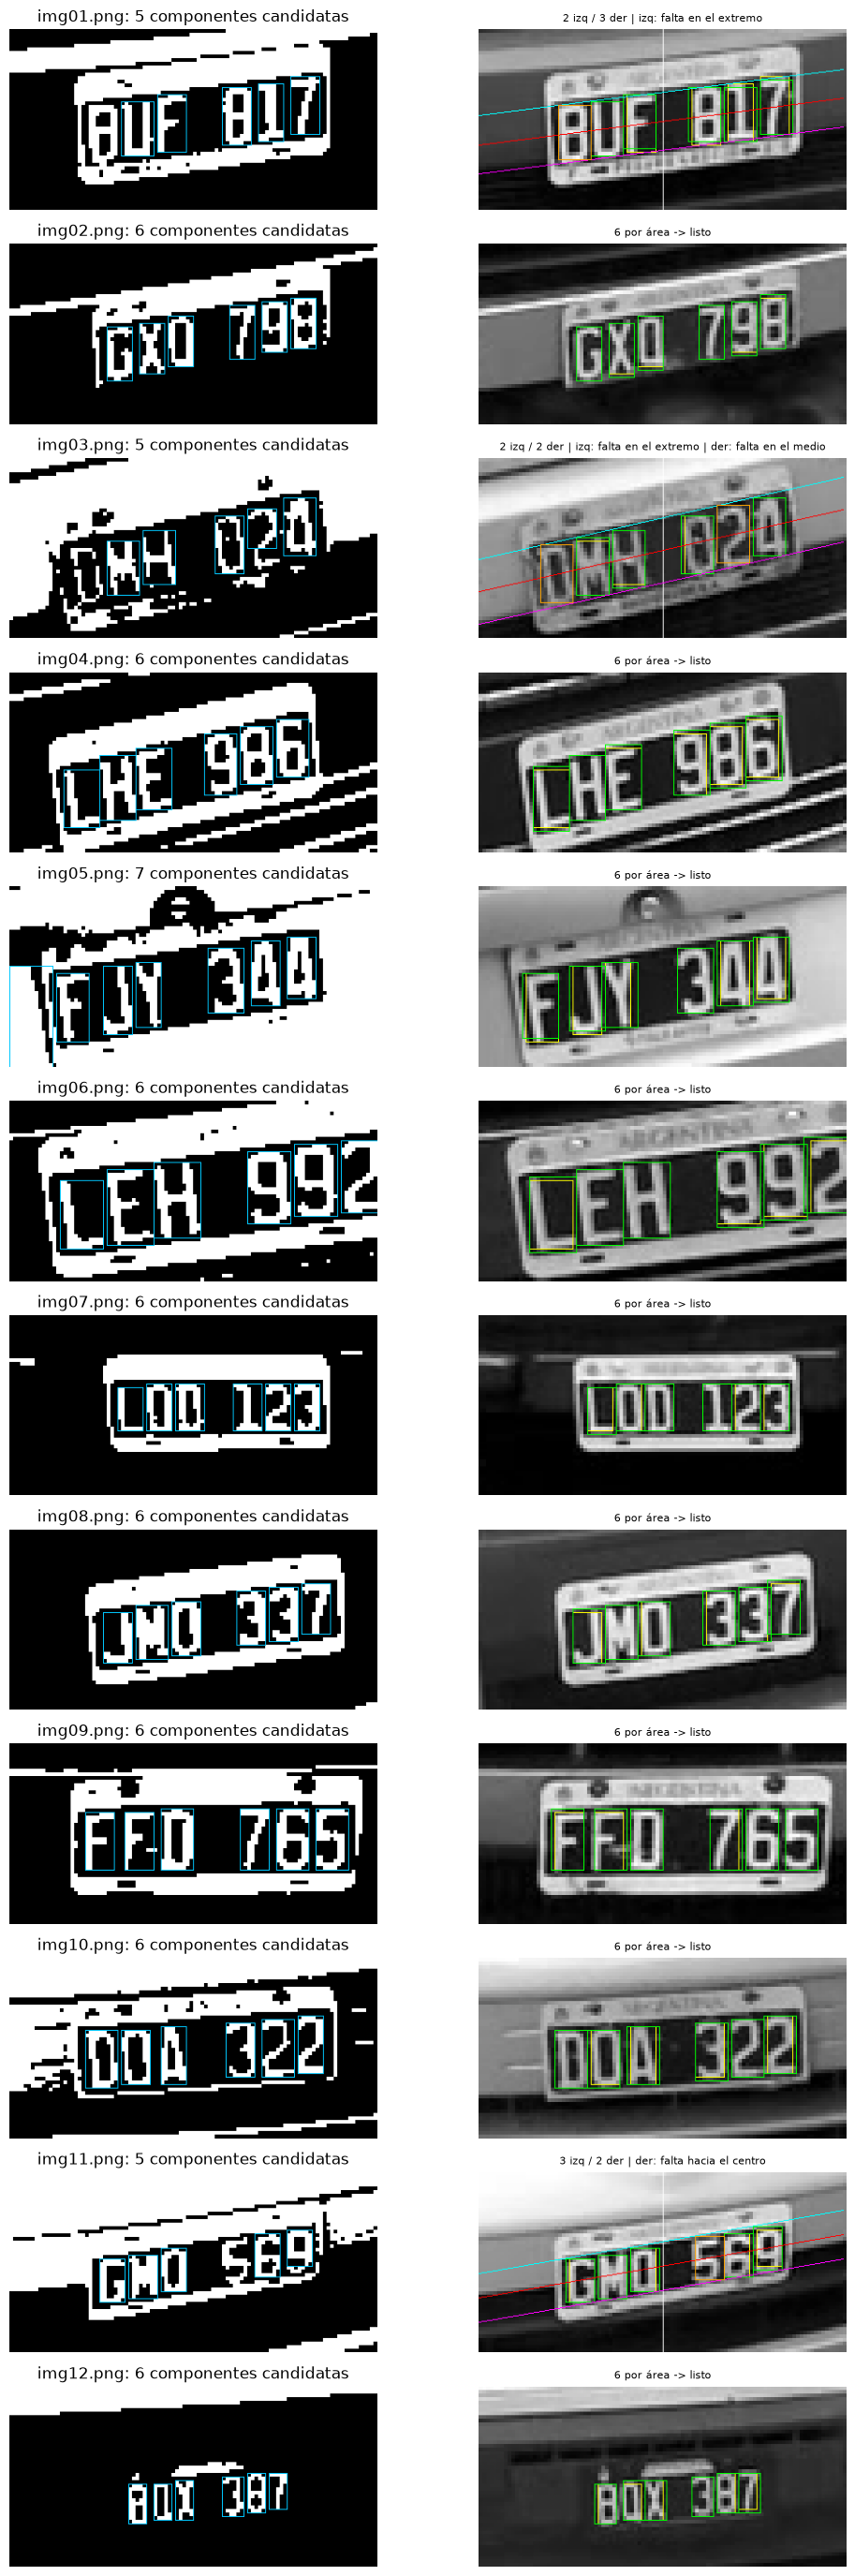

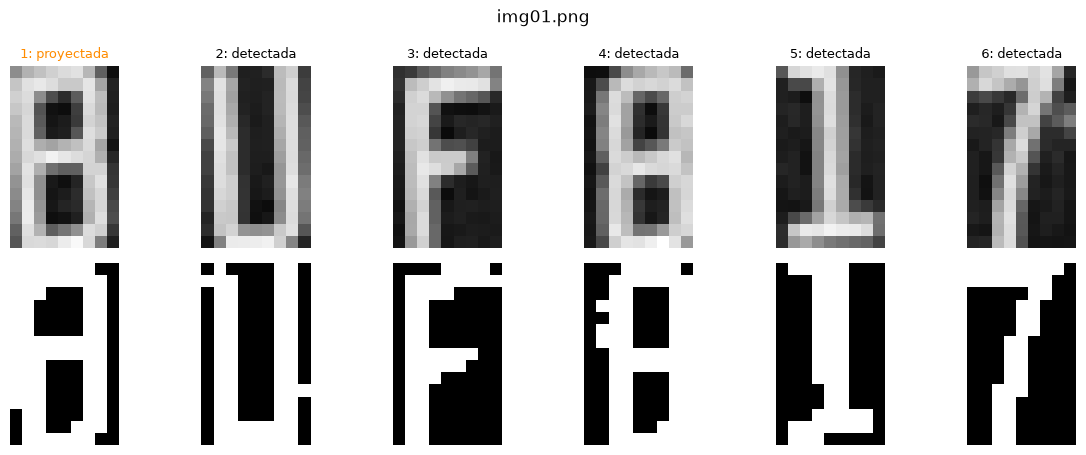

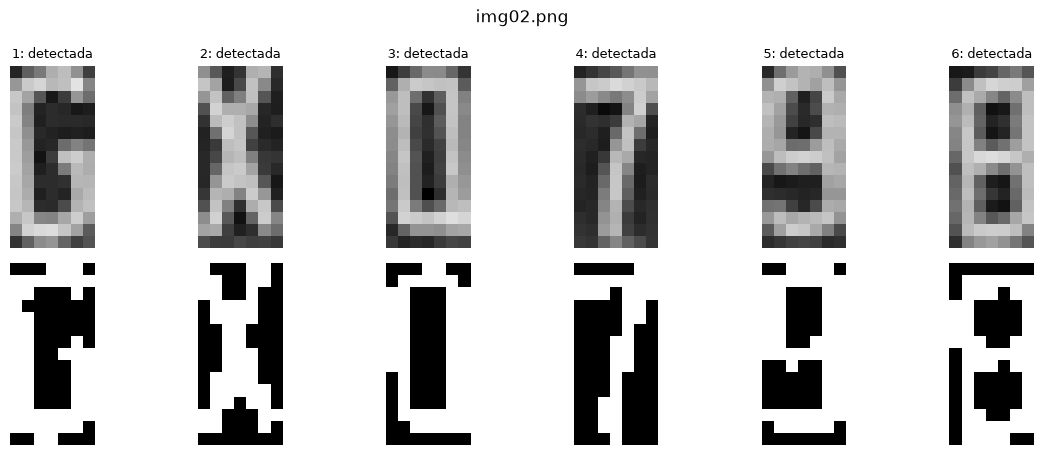

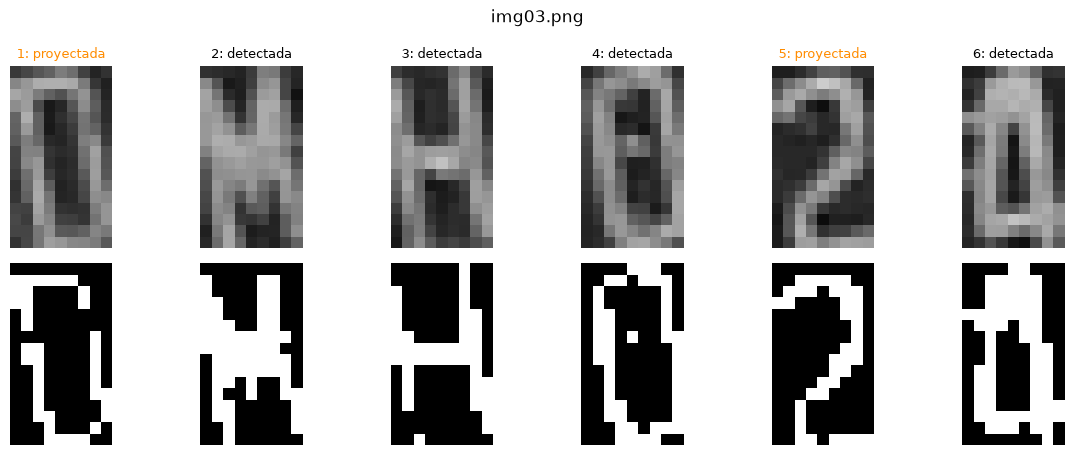

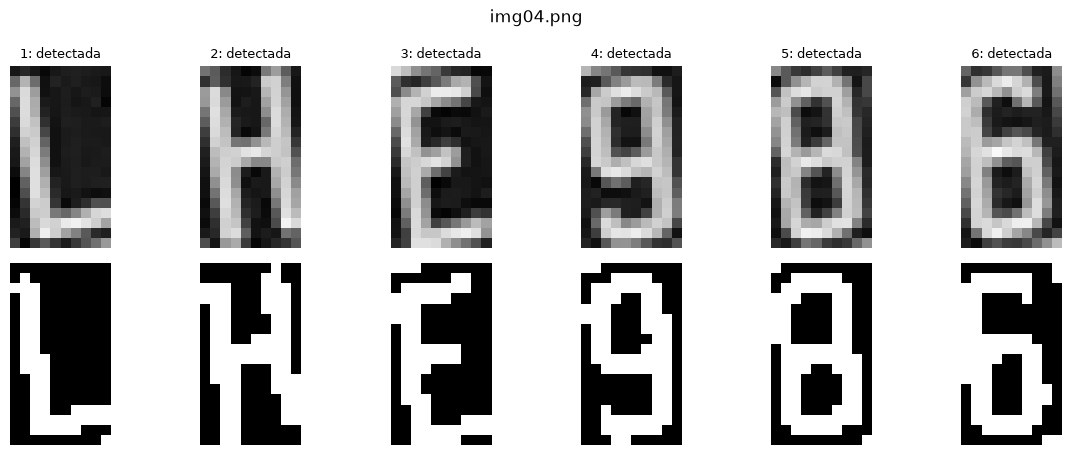

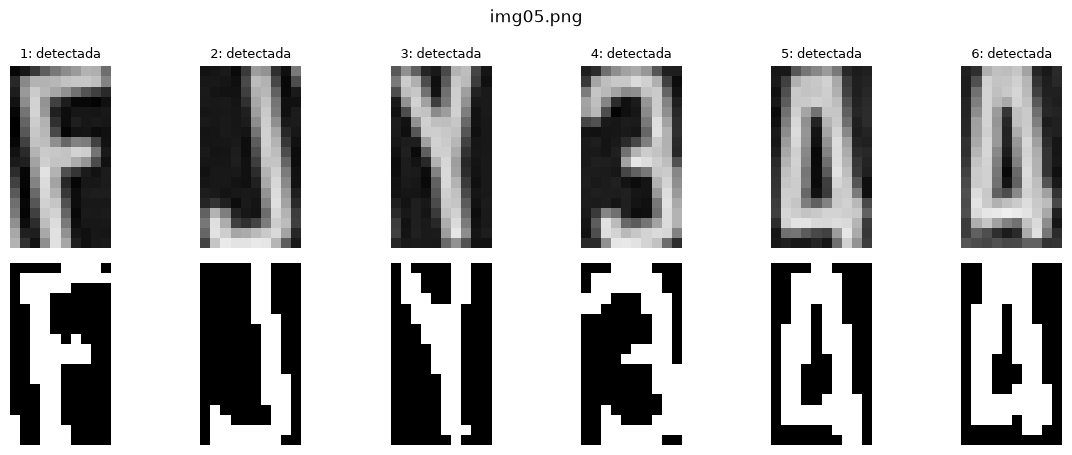

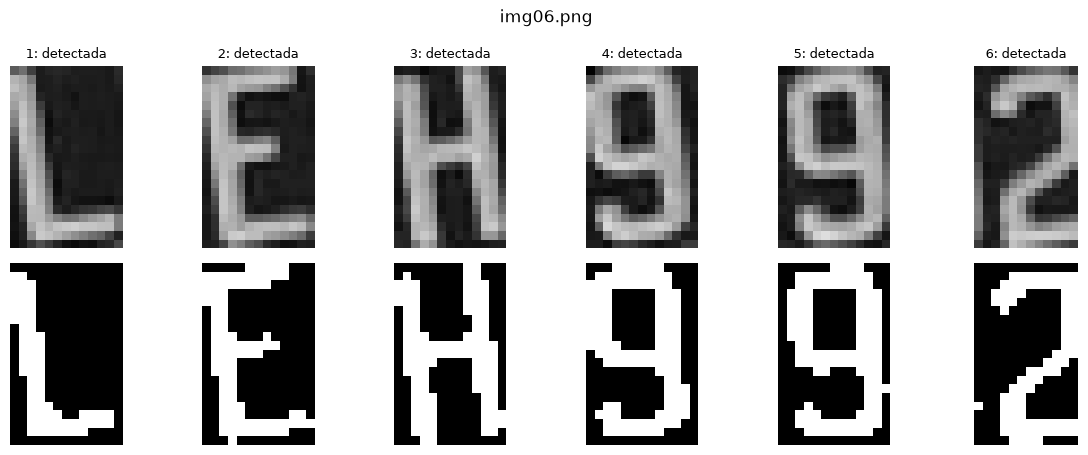

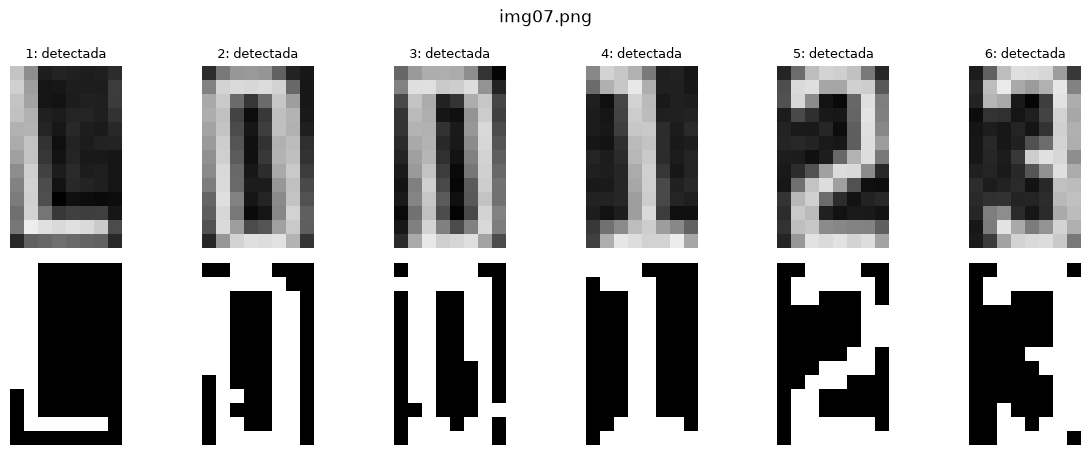

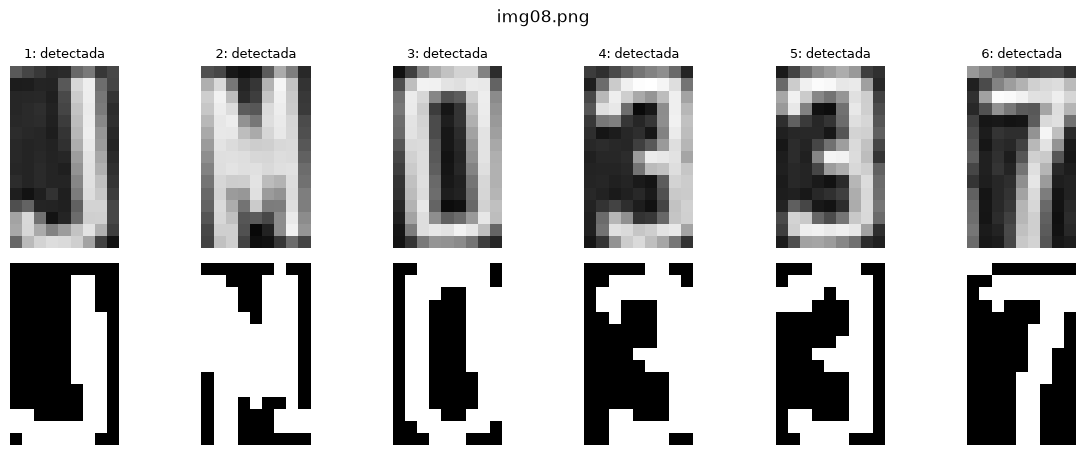

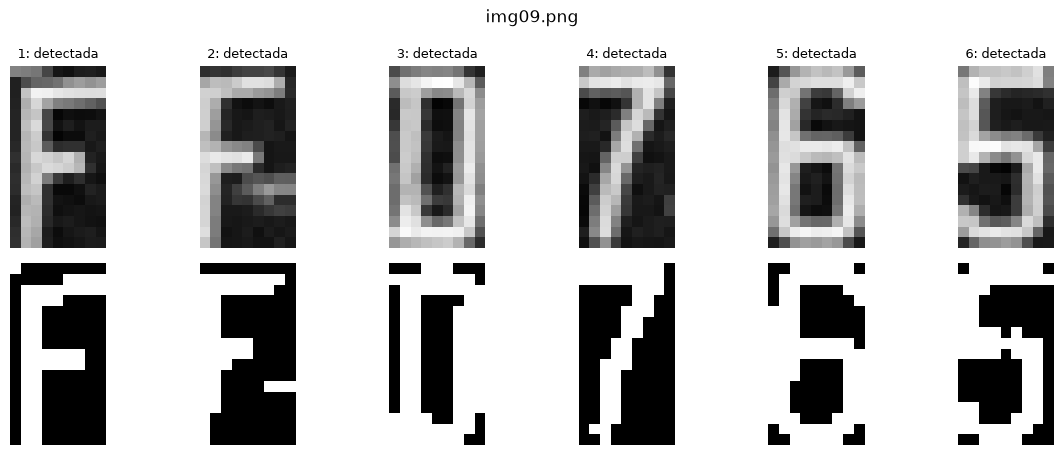

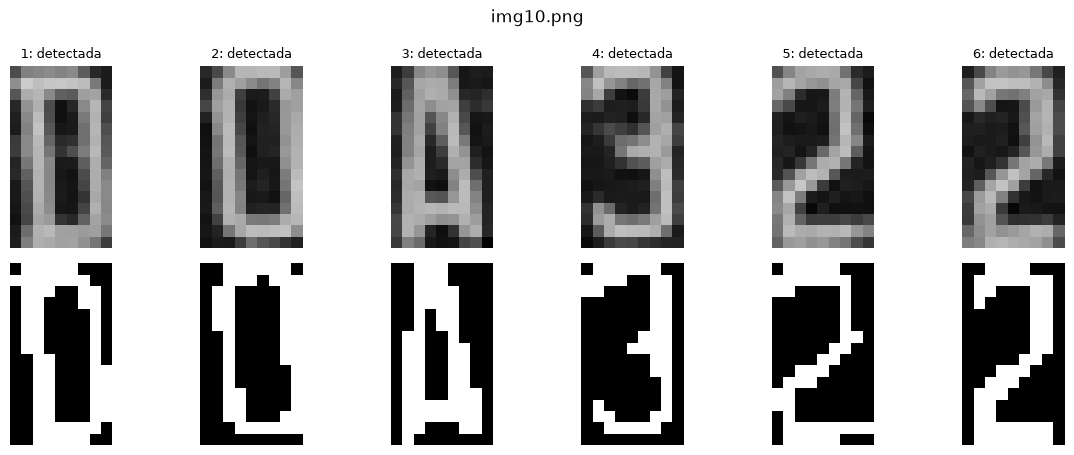

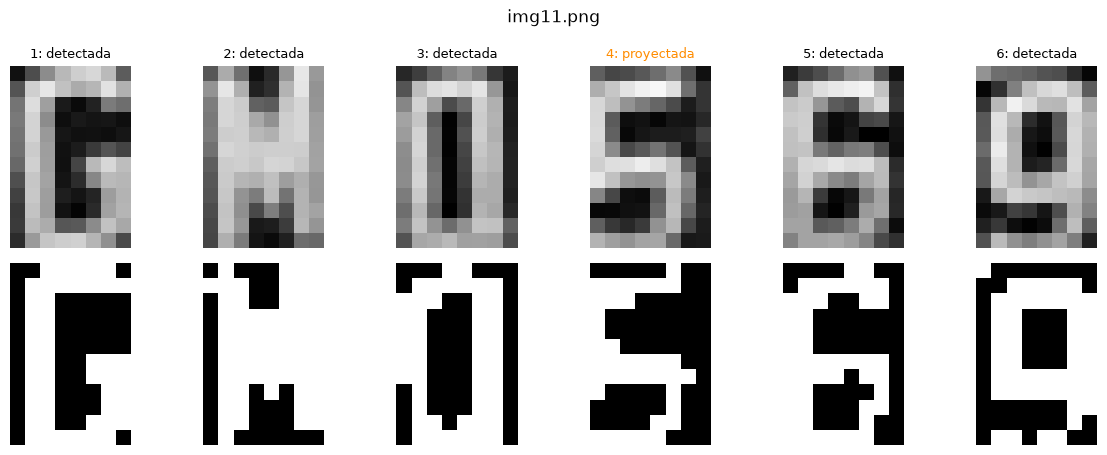

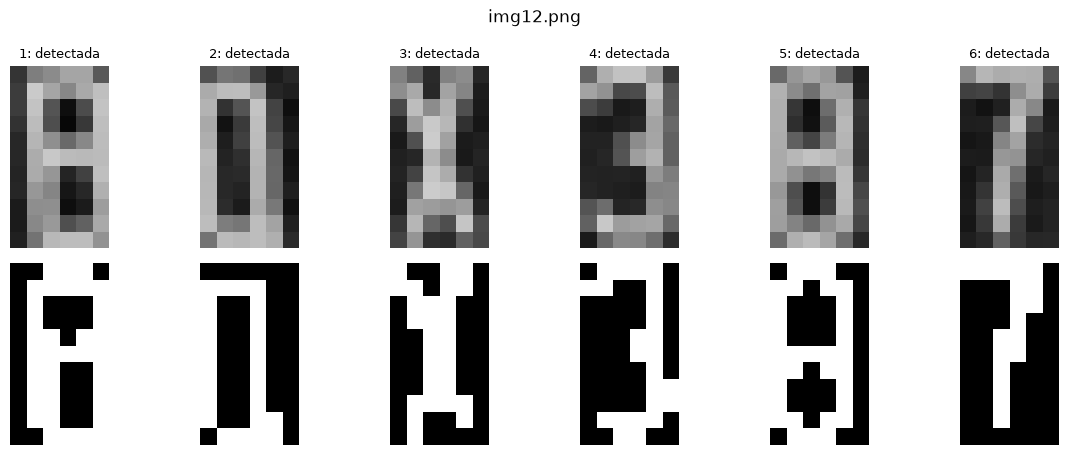

In [72]:
def proyectar_lado(lado, mitad, s, margen=1.5):
    """lado: componentes de un lado de la línea del 50%. s=+1 derecha, s=-1 izquierda.
    Con 2 componentes devuelve (cx, w, h, motivo) de la que falta; con otra cantidad devuelve None."""
    if len(lado) != 2:
        return None
    # u = distancia horizontal a la línea del 50%, medida "hacia afuera" (así izquierda y derecha son análogas)
    A, B = sorted(lado, key=lambda c: s * (c[4] - mitad))        # A = la más cercana a la línea, B = la más lejana
    uA, uB = s * (A[4] - mitad), s * (B[4] - mitad)
    d = uB - uA                                                    # distancia entre centros (el "paso" de la patente)
    hueco = (uB - B[2] / 2) - (uA + A[2] / 2)                      # espacio libre entre las dos cajas (borde a borde)
    w, h = (A[2] + B[2]) / 2, (A[3] + B[3]) / 2
    if hueco >= w:                                                 # están separadas: la que falta está en el medio
        u_nuevo, motivo = (uA + uB) / 2, "en el medio"
    elif uA > margen * d:                                          # entre A y la línea entra otra: falta la del lado de la línea
        u_nuevo, motivo = uA - d, "hacia el centro"
    else:                                                          # no entra: falta la última del extremo
        u_nuevo, motivo = uB + d, "en el extremo"
    return mitad + s * u_nuevo, w, h, motivo


def igualar_cajas(cajas):
    """Fuerza que todas las cajas tengan el tamaño de la más grande (la de mayor área).
    Cada caja nueva se construye con ese tamaño, centrada en el centro de la caja original."""
    if not cajas:
        return []
    _, _, W, H, _, _ = max(cajas, key=lambda c: c[2] * c[3])          # ancho y alto de la caja más grande
    nuevas = []
    for _, _, _, _, cx, cy in cajas:
        x, y = int(round(cx - W / 2)), int(round(cy - H / 2))
        nuevas.append((x, y, W, H, x + W / 2, y + H / 2))
    return nuevas


def ver_por_lados(rutas, umbral=127, factor=4, tol=0.25, margen=1.5):
    fig, ejes = plt.subplots(len(rutas), 2, figsize=(11, 2.3 * len(rutas)))
    ejes = np.atleast_2d(ejes)
    salida = []                                                # por foto: (ruta, estirado, binaria, cajas finales)
    for fila, ruta in zip(ejes, rutas):
        recorte, estirado, binaria = preparar_foto(ruta, umbral=umbral)
        H, W = binaria.shape
        mitad = W / 2
        comp = componentes(binaria)
        originales, ref = cajas_de_area_similar(comp, tol)
        grupo = igualar_cajas(originales)                      # todas del tamaño de la más grande

        vis_bin = cv2.resize(cv2.cvtColor(binaria, cv2.COLOR_GRAY2BGR), None, fx=factor, fy=factor,
                             interpolation=cv2.INTER_NEAREST)
        for x, y, w, h, _, _ in comp:
            cv2.rectangle(vis_bin, (x * factor, y * factor), ((x + w) * factor, (y + h) * factor), (255, 200, 0), 1)
        fila[0].imshow(cv2.cvtColor(vis_bin, cv2.COLOR_BGR2RGB))
        fila[0].set_title(f"{ruta[-9:]}: {len(comp)} componentes candidatas"); fila[0].axis("off")

        vis = cv2.resize(cv2.cvtColor(estirado, cv2.COLOR_GRAY2BGR), None, fx=factor, fy=factor,
                         interpolation=cv2.INTER_NEAREST)
        for x, y, w, h, _, _ in originales:                    # cajas originales (amarillo, para comparar)
            cv2.rectangle(vis, (x * factor, y * factor), ((x + w) * factor, (y + h) * factor), (0, 255, 255), 1)
        for x, y, w, h, _, _ in grupo:                         # cajas igualadas (verde)
            cv2.rectangle(vis, (x * factor, y * factor), ((x + w) * factor, (y + h) * factor), (0, 255, 0), 1)

        cajas_finales = [(x, y, x + w, y + h, "detectada") for x, y, w, h, _, _ in grupo]   # (x0, y0, x1, y1, tipo)

        if len(grupo) == 6:
            titulo = "6 por área -> listo"
        elif len(grupo) < 2:
            titulo = f"{len(grupo)} por área: no alcanza"
        else:
            cv2.line(vis, (int(mitad * factor), 0), (int(mitad * factor), H * factor), (255, 255, 255), 1)   # línea del 50%
            c1, c2 = grupo[0], grupo[-1]
            pend = (c2[5] - c1[5]) / (c2[4] - c1[4])
            trazar_recta(vis, (c1[4], c1[5]), pend, W, factor, (0, 0, 255))                    # centros
            trazar_recta(vis, (c1[0], c1[1]), pend, W, factor, (255, 255, 0))                  # techo (esq. sup. izq.)
            trazar_recta(vis, (c1[0] + c1[2], c1[1] + c1[3]), pend, W, factor, (255, 0, 255))  # piso (esq. inf. der.)
            techo = lambda x: c1[1] + pend * (x - c1[0])
            piso = lambda x: c1[1] + c1[3] + pend * (x - (c1[0] + c1[2]))

            izq = [c for c in grupo if c[4] < mitad]
            der = [c for c in grupo if c[4] >= mitad]
            partes = [f"{len(izq)} izq / {len(der)} der"]
            for nombre, lado, s in (("izq", izq, -1), ("der", der, +1)):
                r = proyectar_lado(lado, mitad, s, margen)
                if r is None:
                    if len(lado) != 3:
                        partes.append(f"{nombre}: {len(lado)} (no se proyecta)")
                    continue
                cx, w, h, motivo = r
                xl, xr = cx - w / 2, cx + w / 2
                esq_sup_izq = (int(xl * factor), int(techo(xl) * factor))   # la recta celeste fija la esquina superior izquierda
                esq_inf_der = (int(xr * factor), int(piso(xr) * factor))    # la recta magenta fija la esquina inferior derecha
                cv2.rectangle(vis, esq_sup_izq, esq_inf_der, (0, 165, 255), 1)   # caja proyectada (naranja), rectangular
                cajas_finales.append((xl, techo(xl), xr, piso(xr), "proyectada"))
                partes.append(f"{nombre}: falta {motivo}")
            titulo = " | ".join(partes)
        fila[1].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); fila[1].set_title(titulo, fontsize=8); fila[1].axis("off")
        salida.append((ruta, estirado, binaria, sorted(cajas_finales)))      # ordenadas de izquierda a derecha
    plt.tight_layout()
    plt.show()
    return salida


def ver_digitos(salida):
    """Una figura por vehículo con el recorte de cada caja (detectada o proyectada), de izquierda a derecha.
    Fila de arriba: recorte en grises (contraste estirado). Fila de abajo: recorte binario.
    El título de cada recorte indica si la caja fue detectada o proyectada (la proyectada va en naranja)."""
    for ruta, estirado, binaria, cajas in salida:
        H, W = binaria.shape
        n = max(len(cajas), 1)
        fig, ejes = plt.subplots(2, n, figsize=(2.0 * n, 4.6), squeeze=False)
        for j, (x0, y0, x1, y1, tipo) in enumerate(cajas):
            x0, y0 = max(0, int(round(x0))), max(0, int(round(y0)))              # recortar sin salirse del recorte
            x1, y1 = min(W, int(round(x1))), min(H, int(round(y1)))
            for i, (img, nombre) in enumerate(((estirado, "grises"), (binaria, "binaria"))):
                ax = ejes[i, j]
                ax.imshow(img[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255)
                ax.axis("off")
                if i == 0:
                    ax.set_title(f"{j + 1}: {tipo}", fontsize=9, color="darkorange" if tipo == "proyectada" else "black")
        fig.suptitle(ruta[-9:])
        plt.tight_layout()
        plt.show()


rutas = [f"../images/Patentes/img{i:02d}.png" for i in range(1, 13)]
salida = ver_por_lados(rutas)
ver_digitos(salida)